# Light Deflection versus the Cosmological Constant

Photon trajectories in Kerr–de Sitter spacetime are integrated with RK4 from Hamilton's equations for
$H = \tfrac12 g^{\mu\nu} p_\mu p_\nu$, for several values of the cosmological constant $\Lambda$ at fixed spin.
The physics code lives in the `kerr_ds` package (`src/kerr_ds/`); see `docs/METHODOLOGY.md` for the full methodology.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

from kerr_ds import (
    kerr_horizon_radius,
    run_lambda_sweep,
    plot_trajectories,
    plot_hamiltonian_vs_step,
    plot_hamiltonian_vs_r,
    fit_curve,
    power_law,
    plot_lambda_fit,
)

## Parameters

In [2]:
# Physical parameters
M = 1.0
a = 0.99
lambdas = [0.0, 1e-8, 5e-8, 1e-7, 5e-7, 1e-6, 5e-6]

# Initial position of the photon
r0 = 500.0
theta0 = np.pi / 2
phi0 = 0.0

# Photon energy and impact parameter (L = b E)
E = 1.0
b = 7
L_ang = b * E

# Integration parameters
dtau = 0.05
max_steps = 30000

# Event-horizon radius for plotting and the capture condition (Kerr approximation)
rh = kerr_horizon_radius(M, a)

## Simulation

The Hamiltonian is derived symbolically **once** (once per machine, usually in about a minute, then loaded from the cache in `~/.cache/kerr_ds/`); each value of $\Lambda$ is then integrated in parallel.

In [3]:
results = run_lambda_sweep(M, a, lambdas, r0, theta0, phi0, E, L_ang, rh,
                           dtau=dtau, max_steps=max_steps)

a          | Lambda     | Deflection (deg)     | Status
-------------------------------------------------------


0.99       | 0.0        | 43.9149              | Steps: 20140


0.99       | 1e-08      | 43.9151              | Steps: 20140


0.99       | 5e-08      | 43.9159              | Steps: 20140


0.99       | 1e-07      | 43.9169              | Steps: 20140


0.99       | 5e-07      | 43.9252              | Steps: 20140


0.99       | 1e-06      | 43.9359              | Steps: 20140


0.99       | 5e-06      | 44.0355              | Steps: 20140


## Photon trajectories

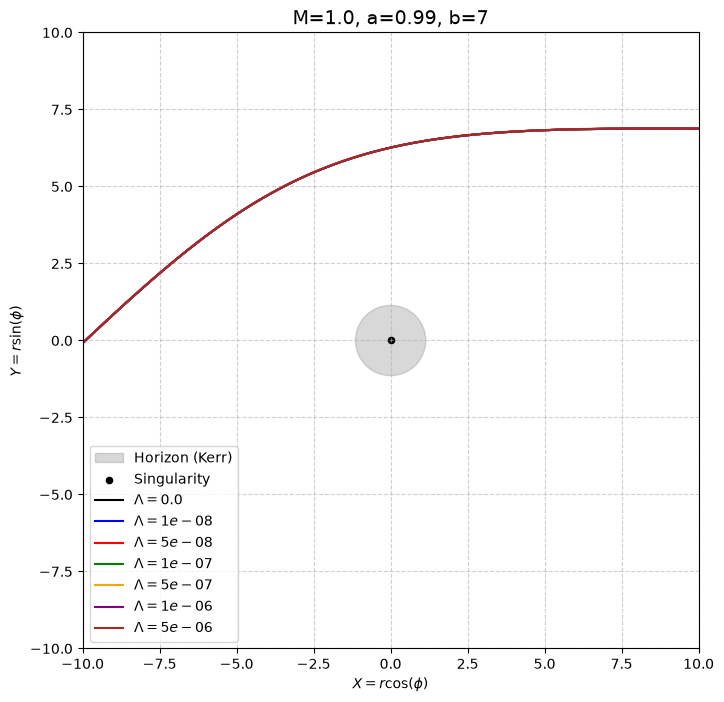

In [4]:
plot_trajectories(results, M, a, b, rh)
plt.show()

## Hamiltonian conservation (last trajectory)

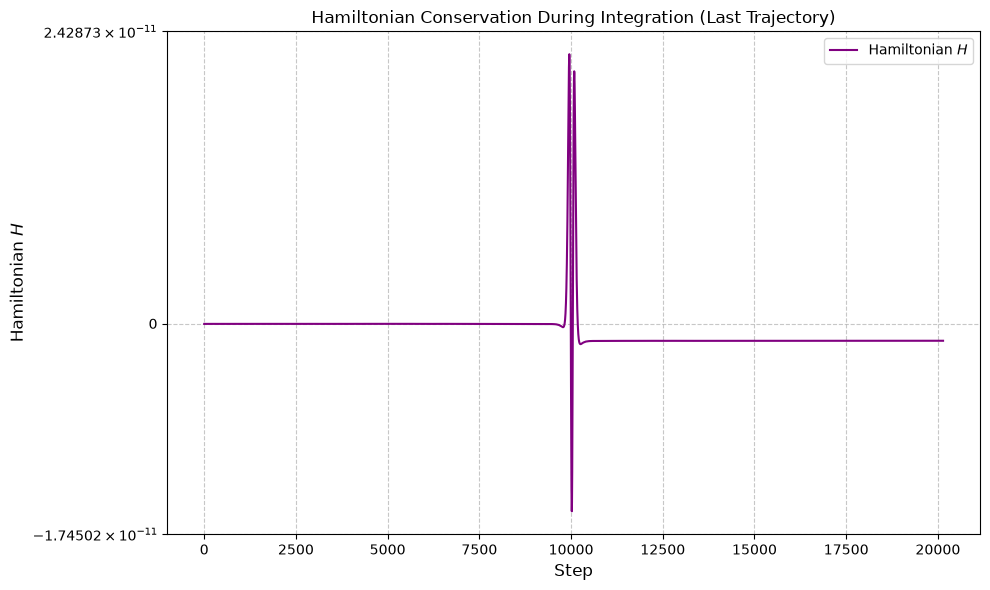

In [5]:
last = results[-1]

plot_hamiltonian_vs_step(last)
plt.show()

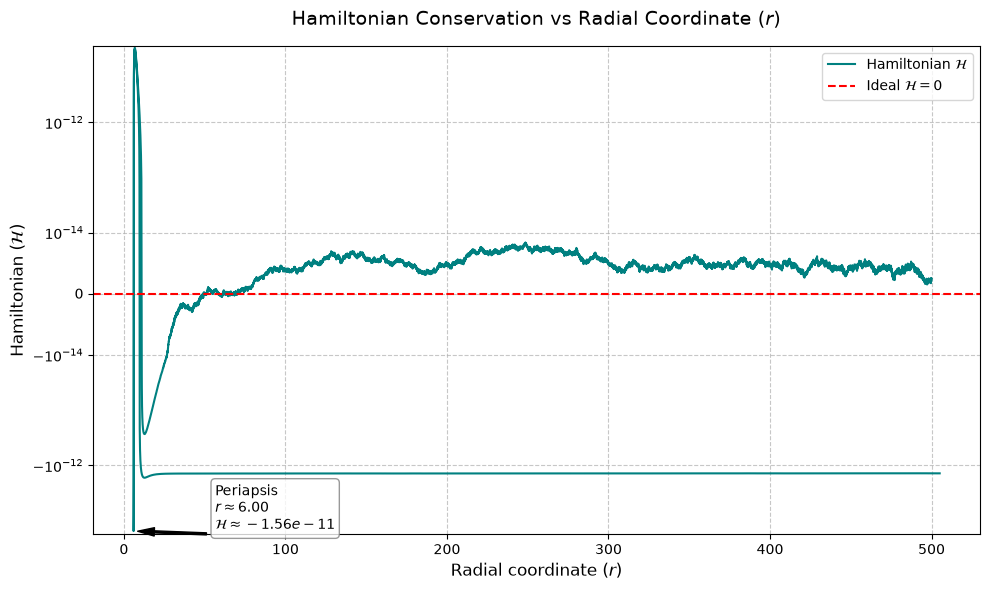

In [6]:
plot_hamiltonian_vs_r(last)
plt.show()

## Deflection versus $\Lambda$: power-law fit

The deflection angles in `results` above are fitted with the nonlinear model
$\delta(\Lambda) = A\,\Lambda^{B} + C$ (`scipy.optimize.curve_fit`), and the fit quality is given by the
coefficient of determination $R^2 = 1 - SS_\text{res}/SS_\text{tot}$.
The point $\Lambda = 0$ is represented by $\Lambda = 10^{-10}$ so that it can be shown on a logarithmic axis
(this changes the deflection by only $\sim 2\times10^{-6}$ degrees).

--- Nonlinear fit results ---
Model: y = 67445.7545 * (Lambda^1.0844) + 43.9150
R² (coefficient of determination) = 0.999985


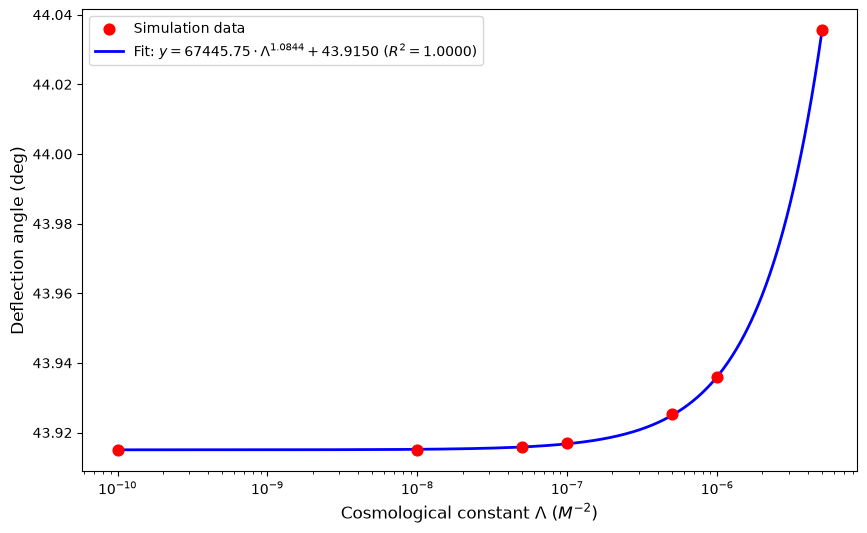

In [7]:
lmd_arr = np.array([res.lmd for res in results])
defl_arr = np.array([res.deflection_deg for res in results])

# Represent Lambda = 0 by 1e-10 so it can be shown on a log axis
lmd_fit = np.where(lmd_arr == 0, 1e-10, lmd_arr)

# Initial guess: B ~ 1 (nearly linear trend), C ~ deflection at the smallest Lambda
p0 = [5000, 1.0, defl_arr[np.argmin(lmd_fit)]]
popt, r2 = fit_curve(power_law, lmd_fit, defl_arr, p0=p0, maxfev=20000)
A_opt, B_opt, C_opt = popt

print("--- Nonlinear fit results ---")
print(f"Model: y = {A_opt:.4f} * (Lambda^{B_opt:.4f}) + {C_opt:.4f}")
print(f"R² (coefficient of determination) = {r2:.6f}")

plot_lambda_fit(lmd_fit, defl_arr, popt, r2)
plt.show()